# Full EWA B-Spline PDE Solver Experiment

### Overview of All 12 Benchmark Suites in `examples/`

This notebook tests the robust `EWABSplinePDE` solver across all 12 benchmark PDE suites in `examples/`:


| # | Benchmark Name | PDE Type | Boundary Condition | Domain $\Omega$ | Forcing Term $g(x, y)$ | True Solution $u(x, y)$ |
|:--|:---|:---|:---|:---|:---|:---|
| **1** | **`AnisoHelmholtzDir`** | $u_{xx} + \alpha u_{yy} + \beta u = 0$ | Dirichlet | $[0, 1] \times [0, 1]$ | $0$ (Homogeneous) | $u = a_1 \cos(m_1\pi x) \cos(n_1\pi y) + a_2 \sin(m_2\pi x) \sin(n_2\pi y)$ |
| **2** | **`NuclearDir`** | $-\nabla \cdot (D \nabla \phi) + (\Sigma_a - \nu\Sigma_f)\phi = S$ | Dirichlet | $[0, 100] \times [0, 100]$ | $\sum_{k=1}^3 A_k p_{\text{sm}} e^{-\|\mathbf{x}-\mathbf{x}_k\|^2/\sigma_k^2}$ | FD Reactor Solver $\phi(x, y)$ ($121 \times 121$ cubic interp.) |
| **3** | **`WaveDir`** | $u_{yy} - c^2 u_{xx} = 0$ | Dirichlet | $[0, 1] \times [0, 1]$ | $0$ (Homogeneous) | $u = a_1 \sin(k_1 x) \cos(\omega_1 y) + a_2 \sin(k_2 x) \cos(\omega_2 y)$ |
| **4** | **`TransportDir`** | $\alpha u_{xx} + c_x u_x + c_y u_y = g$ | Dirichlet | $[0, 1] \times [0, 1]$ | $c_x u_x + c_y u_y$ | $u = a_1 \sin(m_1 \pi x) \sin(m_1 \pi y) + a_2 \sin(m_2 \pi x) \sin(m_2 \pi y)$ |
| **5** | **`CornerSingDir`** | $u_{xx} + c u_{yy} = 0$ | Dirichlet | $[0, 1] \times [0, 1]$ | $0$ (Homogeneous) | $u = \text{scale} \cdot r^{2/3} \sin\left(\frac{2}{3} \theta\right) = \text{Im}((x+iy)^{2/3})$ |
| **6** | **`PoissonDir`** | $u_{xx} + a^2 u_{yy} = g$ | Dirichlet | $[0, 2\pi] \times [0, \pi]$ | $K \cos(m_2 x) \cos(n_2 y)$ | $u = -\frac{K}{m_2^2 + a^2 n_2^2} \cos(m_2 x) \cos(n_2 y)$ |
| **7** | **`DegenEllipNeu`** | $u_{xx} + b u_{xy} + c u_{yy} = g$ | Neumann | $[0, 1] \times [0, 1]$ | $u_{xx} + b u_{xy} + c u_{yy}$ | $u = a_1 \cos(m\pi x) \cos(n\pi y) + a_2 \cos(n\pi x) \cos(m\pi y)$ |
| **8** | **`ConstNeu`** | $u_{xx} + c u_{yy} = 0$ | Neumann | $[0, 1] \times [0, 1]$ | $0$ (Homogeneous) | $u \equiv 0$ (Zero-Signal / Noise Only) |
| **9** | **`HighHelmholtzNeu`** | $u_{xx} + u_{yy} + k^2 u = 0$ | Neumann | $[0, 1] \times [0, 1]$ | $0$ (Homogeneous) | $u = a_1 \cos(m\pi x) \cos(n\pi y) + a_2 \cos(n\pi x) \cos(m\pi y)$ |
| **10** | **`HighPecletNeu`** | $\alpha u_{xx} + u_{yy} - v u_x = 0$ | Dirichlet | $[0, 1] \times [0, 1]$ | $0$ (Homogeneous) | $u = X_1(x) \sin(\pi y) + X_2(x) \sin(2\pi y)$ |
| **11** | **`TelegraphNeu`** | $u_{yy} + 2\gamma u_y - c^2 u_{xx} = g$ | Neumann | $[0, 2\pi] \times [0, \pi]$ | $K(c^2 m_2^2 - n_2^2 - \gamma^2) e^{-\gamma y} \sin(m_2 x) \cos(n_2 y)$ | $u = K e^{-\gamma y} \sin(m_2 x) \cos(n_2 y)$ |
| **12** | **`CollinHarmNeu`** | $u_{xx} + c u_{yy} + d u_x = 0$ | Neumann | $[0, 1] \times [0, 1]$ | $0$ (Homogeneous) | $u = \text{amp} \cdot e^{k x} \sin(k y)$ |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path
import importlib
import runpy

home_dir = Path.home()
proj_dir = home_dir / 'PycharmProjects' / 'EWABsplinePDE'
sys.path.append(str(proj_dir))

import util
from ewa import EWABSplinePDE
import run_example

import warnings
import logging
import os
from contextlib import redirect_stdout
logging.disable(logging.CRITICAL)
warnings.filterwarnings('ignore')

In [2]:
folder = proj_dir / 'examples'
sys.path.append(str(folder))

filenames = [f.stem for f in folder.glob('*.py') if f.name != 'run_example.py']
print("Available PDE Benchmark Suites in examples/:", filenames)

N_ITER = 50
N_list = [3000]

Available PDE Benchmark Suites in examples/: ['NuclearDir', 'WaveDir', 'TransportDir', 'CornerSingDir', 'PoissonDir', 'DegenEllipNeu', 'CollinHarmNeu', 'ConstNeu', 'HighHelmholtzNeu', 'HighPecletNeu', 'TelegraphNeu', 'AnisoHelmholtzDir']


In [3]:
def load_benchmark_module(bench_name: str, file_path: Path):
    spec = importlib.util.spec_from_file_location(bench_name, file_path)
    if spec is None or spec.loader is None:
        raise ImportError(f"Cannot load spec for {bench_name} at {file_path}")
    
    mod = importlib.util.module_from_spec(spec)
    sys.modules[bench_name] = mod
    spec.loader.exec_module(mod)
    return mod

def execute_benchmark(bench, n, w=0, deg=3,
                      n_iter=N_ITER, d=0, b=0):
    assert str(w) in ['0', '1']
    script_path = folder / f"{bench}.py"
    if not script_path.exists():
        print(f"Skipping {bench} (File not found)")
        return pd.DataFrame(), pd.DataFrame()

    # Set CLI arguments for run_pde_experiment
    sys.argv = [
        f'{bench}.py',
        '-n', str(n),
        '-sf', '0.1',
        '-deg', str(deg),
        '-w', str(w),
        '-i', str(n_iter),
        '-s', '0', 
        '-d', str(d),
        '-b', str(b)
    ]

    mod = load_benchmark_module(bench, script_path)

    with open(os.devnull, 'w') as f_null:
        with redirect_stdout(f_null):
            res_df, param_df = run_example.run_pde_experiment(
                pde_name=getattr(mod, 'PDE_NAME'),
                dim=getattr(mod, 'DIM'),
                variables=getattr(mod, 'VARIABLES'),
                pde_params=getattr(mod, 'PDE_PARAMS'),
                true_sol_with_derivatives=getattr(mod, 'true_sol_with_derivatives'),
                boundary_conditions=getattr(mod, 'boundary_conditions'),
                setup_config_func=getattr(mod, 'setup_config_func'),
                x_max_size=getattr(mod, 'X_MAX_SIZE', 1_000_000),
                oversample=getattr(mod, 'OVERSAMPLE', 100),
            )
            
    return res_df, param_df
    
def compare_weak_form(bench, n, n_iter=N_ITER):
    res = {}
    params = {}
    for w in ['0', '1']:
        r, p = execute_benchmark(bench, n, w, n_iter=n_iter)
        res[w] = r
        params[w] = p
    
    res = pd.concat(res, names=['weak']) #bias_correct
    run_example.plot_res_summary(
        res,
        param_df=params,
        pde_name=bench,
        save_path=f'./output/{bench}_{n}.jpg'
    )

def compare_degree(bench, n, n_iter=N_ITER):
    res = {}
    params = {}
    for deg in [3, 4, 5]:
        r, p = execute_benchmark(bench, n, w=1, deg=deg, b=1, n_iter=n_iter)
        res[deg] = r
        params[deg] = p
    
    res = pd.concat(res, names=['degree']) #bias_correct
    run_example.plot_res_summary(
        res,
        param_df=params,
        pde_name=bench,
        save_path=f'./output/DegBiasWeak/{bench}.jpg'
    )


def compare_bias_corr(bench, n, n_iter=N_ITER):
    res = {}
    params = {}
    for b in [0, 1]:
        r, p = execute_benchmark(bench, n, w=0, deg=3, b=b, n_iter=n_iter)
        res[b] = r
        params[b] = p
    
    res = pd.concat(res, names=['bias_correct']) #bias_correct
    run_example.plot_res_summary(
        res,
        param_df=params,
        pde_name=bench,
        save_path=f'./output/BiasStrong/{bench}.jpg'
    )

hypothesis = compare_degree

## 1. Multi-Mode Anisotropic Helmholtz (`AnisoHelmholtzDir.py`)

**PDE:**
$$u_{xx} + \alpha u_{yy} + \beta u = 0$$
where $\alpha = 0.6$, $\beta = (m^2 + \alpha n^2) \pi^2 = (3.2^2 + 0.6 \times 4.7^2)\pi^2 = 23.494\pi^2 \approx 231.87$.

**Params:**
- Modes: $m = 3.2$ (`p_m`), $n = 4.7$ (`p_n`)
- Anisotropy: $\alpha = 0.6$ (`p_alpha`)
- Amplitudes: $a_1 = 1.1$ (`p_a1`), $a_2 = 0.4$ (`p_a2`)
- True parameters: $\beta \approx 231.87$ (`beta`), $\alpha = 0.6$ (`alpha`)

**Boundary Condition:**
Dirichlet (`boundary_conditions = 'dirichlet'`)

**Domain:**
$$\Omega = [0, 1.0] \times [0, 1.0]$$

**Force:**
$$g(x, y) = 0$$

**Solution:**
$$u(x, y) = a_1 \cos(m_1 \pi x) \cos(n_1 \pi y) + a_2 \sin(m_2 \pi x) \sin(n_2 \pi y)$$
where $m_1 = 3.2, n_1 = 4.7, m_2 = \sqrt{\alpha} n = \sqrt{0.6} \times 4.7$, and $n_2 = m / \sqrt{\alpha} = 3.2 / \sqrt{0.6}$.

100%|███████████████████████████████████████████| 50/50 [02:04<00:00,  2.49s/it]


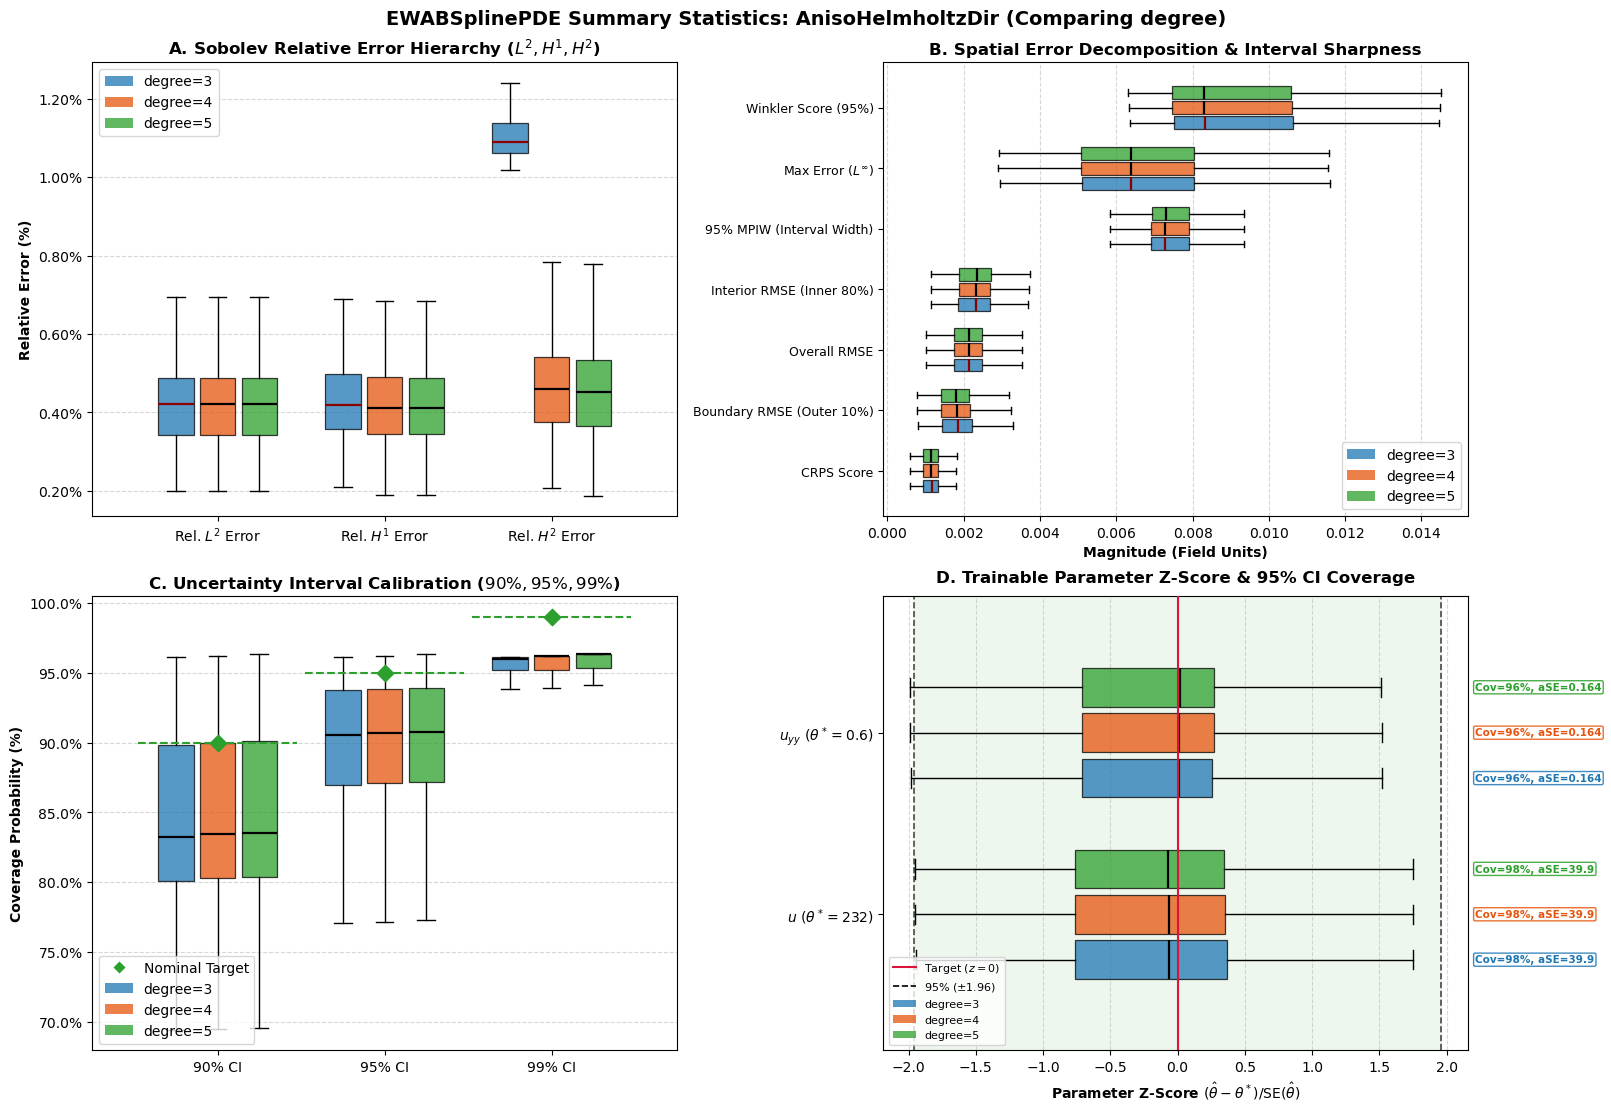

In [4]:
for n in N_list:
    hypothesis('AnisoHelmholtzDir', n=n)                    

## 2. One-Group Steady-State Neutron Diffusion (`NuclearDir.py`)

**PDE:**
$$-\nabla \cdot \big( D(x, y) \nabla \phi(x, y) \big) + \Sigma_a(x, y) \phi(x, y) - \nu\Sigma_f(x, y) \phi(x, y) = S(x, y)$$
where the two-region reactor consists of a central fissile core $\Omega_c = [25, 75]^2$ ($\chi_c = \mathbf{1}_{\Omega_c}$) surrounded by a graphite reflector ($\chi_r = 1 - \chi_c$), with spatially varying material coefficients:
- Diffusion coefficient: $D(x, y) = 1.0\,\chi_c(x, y) + D_{\text{ref}}\,\chi_r(x, y)$
- Macroscopic absorption cross-section: $\Sigma_a(x, y) = 0.07\,\chi_c(x, y) + 0.001\,\chi_r(x, y)$
- Macroscopic fission production: $\nu\Sigma_f(x, y) = (\nu\Sigma_f)_{\text{core}}\,\chi_c(x, y)$

**Params:**
- Reflector diffusion coefficient: $D_{\text{ref}} = 0.9$ (`p_rf`, flag `--reflector_D`)
- Core fission production: $(\nu\Sigma_f)_{\text{core}} = 0.060$ (`p_cf`, flag `--core_fission`)
- Source multiplier: $p_{\text{sm}} = 1.0$ (`p_sm`, flag `--source_mult`)
- Domain length: $L = 100.0$ (`p_L`, flag `--bound_L`)
- True operator parameters: `baseline` $= 1.0$ (locked), `reflector_D` $= 0.9$ (trainable), `core_fission` $= 0.060$ (trainable)

**Boundary Condition:**
Dirichlet (`boundary_conditions = 'dirichlet'`, homogeneous $\phi|_{\partial\Omega} = 0$)

**Domain:**
$$\Omega = [0, 100.0] \times [0, 100.0]$$

**Force:**
$$g(x, y) = S(x, y) = \sum_{k=1}^{3} A_k p_{\text{sm}} \exp\!\left(-\frac{(x - x_k)^2 + (y - y_k)^2}{\sigma_k^2}\right)$$
with three Gaussian startup sources: $(x_1, y_1, A_1, \sigma_1^2) = (25, 25, 40, 80)$, $(x_2, y_2, A_2, \sigma_2^2) = (75, 25, 40, 80)$, and $(x_3, y_3, A_3, \sigma_3^2) = (50, 75, 60, 100)$.

**Solution:**
$$u(x, y) = \phi(x, y)$$
computed numerically via the 2D finite-difference reactor solver (`solve_fd_reactor` on a $121 \times 121$ grid) with cubic `RegularGridInterpolator` evaluation for $\phi$ and its spatial derivatives up to order 2.

100%|███████████████████████████████████████████| 50/50 [02:12<00:00,  2.66s/it]


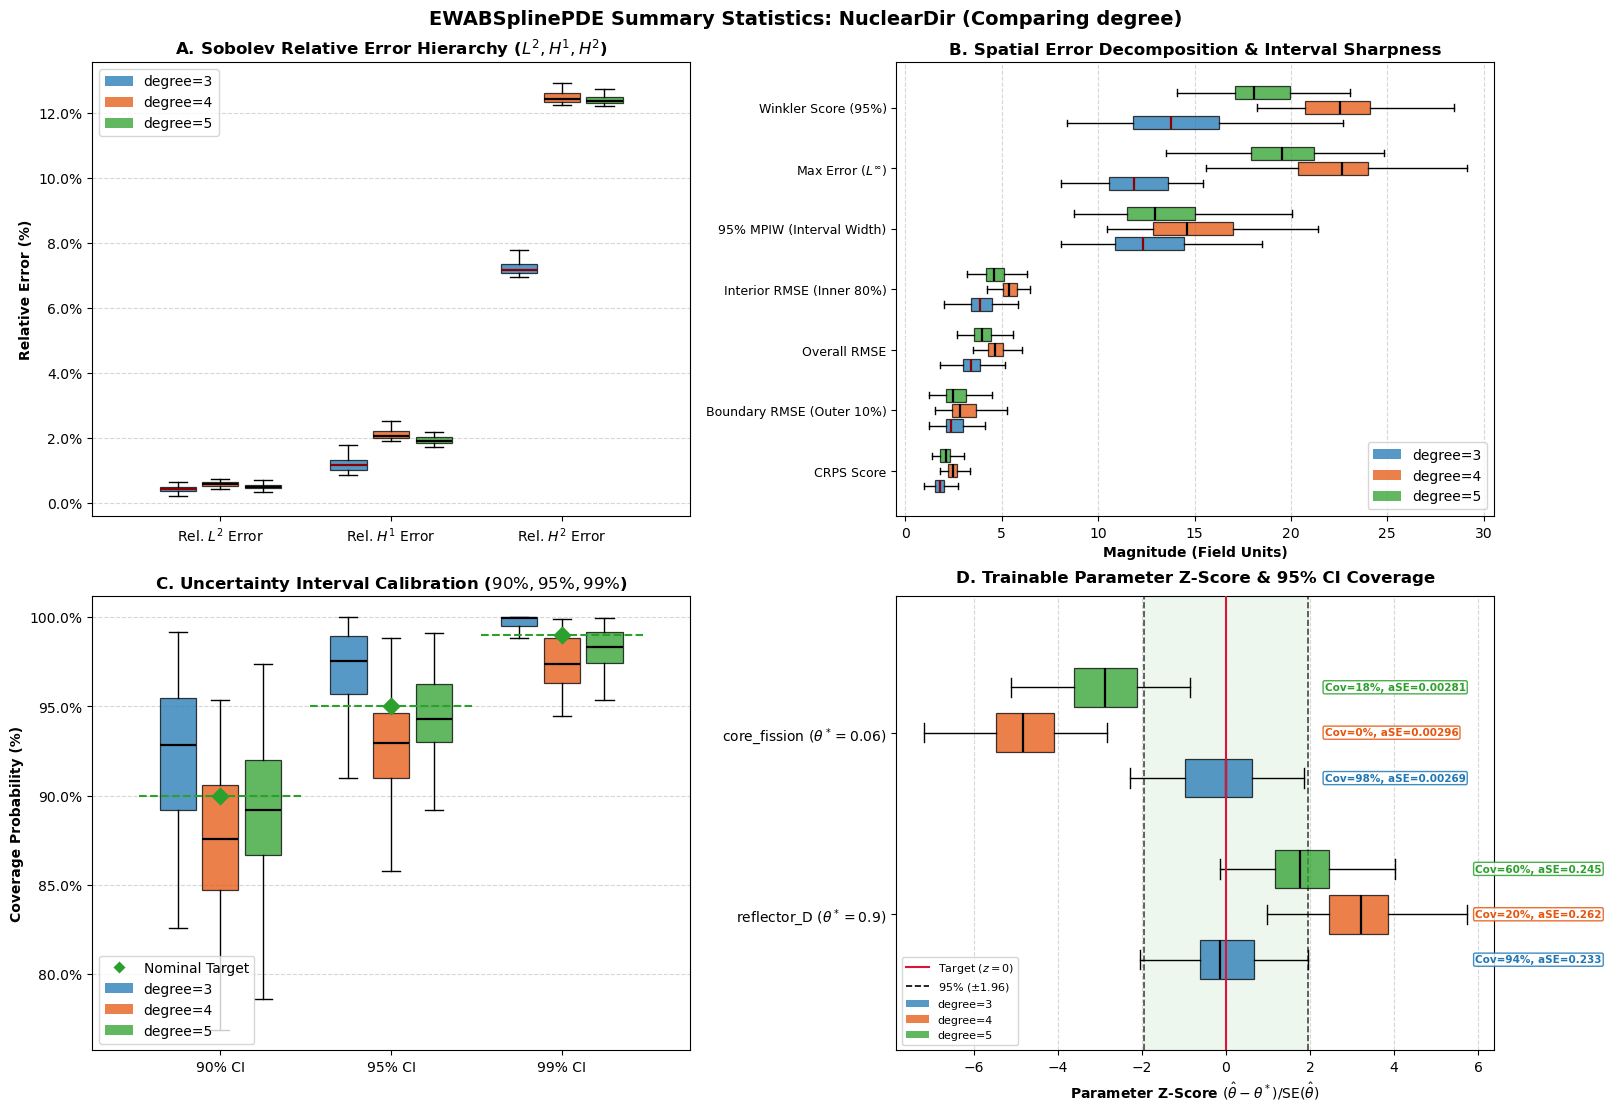

In [5]:
for n in N_list:
    hypothesis('NuclearDir', n=n)

## 2. Space-Time Wave (`WaveDir.py`)

**PDE:**
$$u_{yy} - c^2 u_{xx} = 0 \iff -c^2 u_{xx} + u_{yy} = 0$$

**Params:**
- Wave speed: $c = 1.5$ (`p_c`)
- Spatial wave modes: $m_1 = 1.0$ (`p_m1`), $m_2 = 2.0$ (`p_m2`)
- Modal amplitudes: $a_1 = 1.0$ (`p_a1`), $a_2 = 0.5$ (`p_a2`)
- Domain bounds: $L = 1.0$ (`p_L`), $H = 1.0$ (`p_H`)
- Frequencies: $k_1 = \pi, k_2 = 2\pi$; $\omega_1 = 1.5\pi, \omega_2 = 3.0\pi$

**Boundary Condition:**
Dirichlet (`boundary_conditions = 'dirichlet'`)

**Domain:**
$$\Omega = [0, L] \times [0, H] = [0, 1.0] \times [0, 1.0]$$

**Force:**
$$g(x, y) = 0$$

**Solution:**
$$u(x, y) = a_1 \sin(k_1 x) \cos(\omega_1 y) + a_2 \sin(k_2 x) \cos(\omega_2 y) = 1.0 \sin(\pi x) \cos(1.5\pi y) + 0.5 \sin(2\pi x) \cos(3\pi y)$$

100%|███████████████████████████████████████████| 50/50 [00:57<00:00,  1.16s/it]


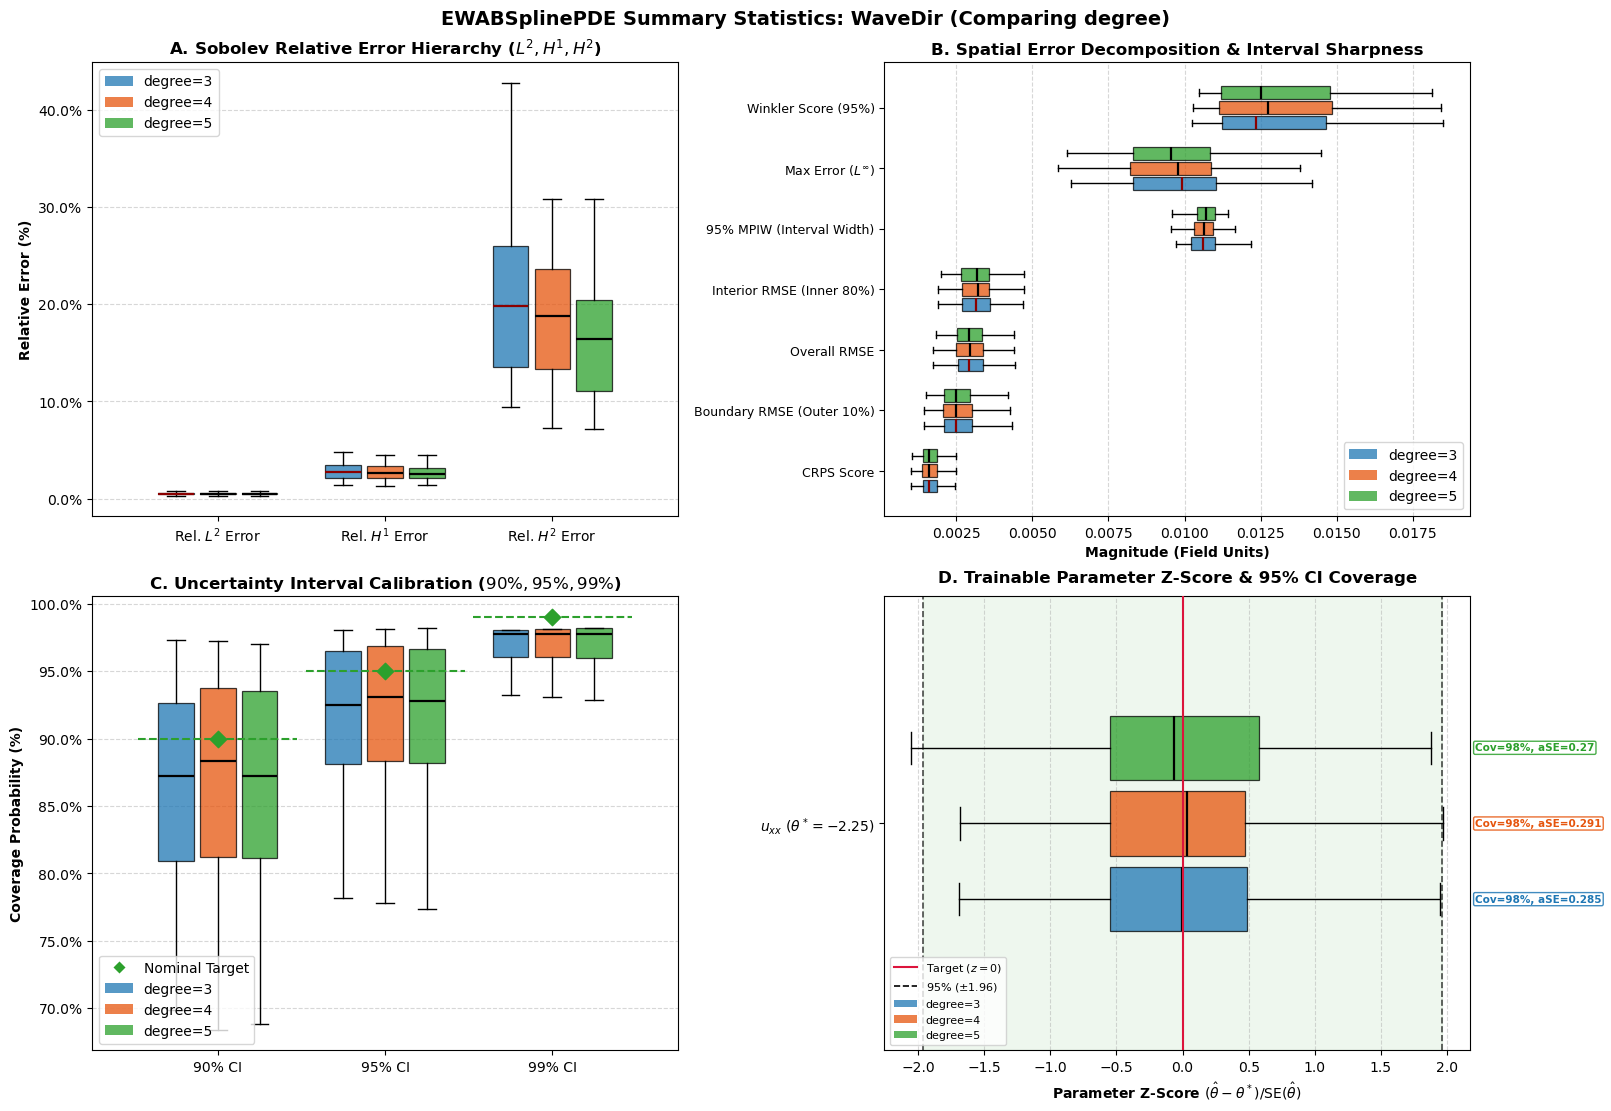

In [6]:
for n in N_list:
    hypothesis('WaveDir', n=n)

## 3. Pure Convective Transport (`TransportDir.py`)

**PDE:**
$$\alpha u_{xx} + c_x u_x + c_y u_y = g(x, y)$$

**Params:**
- Velocity $x$: $c_x = 1.0$ (`p_cx`)
- Velocity $y$: $c_y = 2.0$ (`p_cy`)
- Frequencies: $m_1 = 1.0$ (`p_m1`), $m_2 = 2.0$ (`p_m2`)
- Amplitudes: $a_1 = 1.0$ (`p_a1`), $a_2 = 0.5$ (`p_a2`)
- True parameters: $c_y = 2.0$ (`vel_y`), $\alpha = 0.0$ (`diff_xx`)

**Boundary Condition:**
Dirichlet (`boundary_conditions = 'dirichlet'`)

**Domain:**
$$\Omega = [0, 1.0] \times [0, 1.0]$$

**Force:**
$$g(x, y) = c_x u_x + c_y u_y$$
where $u_x = a_1 k_1 \cos(k_1 x) \sin(k_1 y) + a_2 k_2 \cos(k_2 x) \sin(k_2 y)$ and $u_y = a_1 k_1 \sin(k_1 x) \cos(k_1 y) + a_2 k_2 \sin(k_2 x) \cos(k_2 y)$, with $k_1 = \pi, k_2 = 2\pi$.

**Solution:**
$$u(x, y) = a_1 \sin(m_1 \pi x) \sin(m_1 \pi y) + a_2 \sin(m_2 \pi x) \sin(m_2 \pi y) = 1.0 \sin(\pi x) \sin(\pi y) + 0.5 \sin(2\pi x) \sin(2\pi y)$$

100%|███████████████████████████████████████████| 50/50 [01:30<00:00,  1.80s/it]


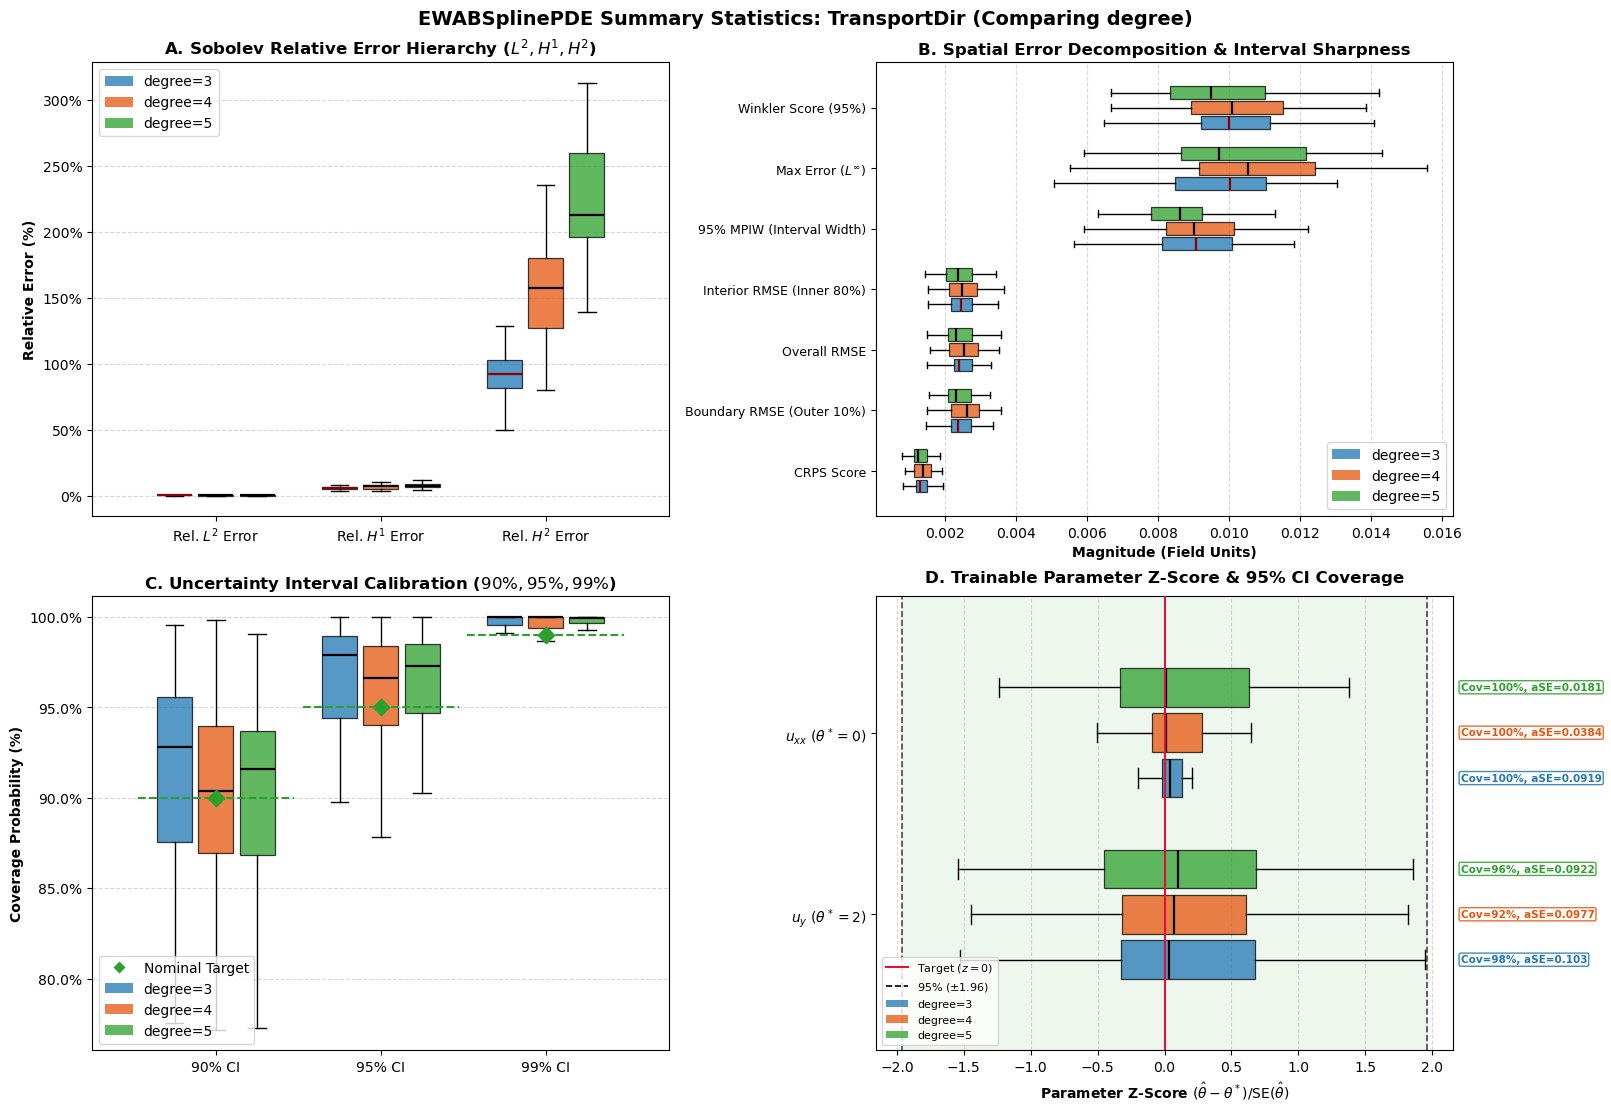

In [7]:
for n in N_list:
    hypothesis('TransportDir', n=n)

## 4. Re-entrant Corner Singularity (`CornerSingDir.py`)

**PDE:**
$$u_{xx} + c u_{yy} = 0$$

**Params:**
- Singularity exponent: $\alpha = 2/3$ (`p_alpha`)
- Scale: $\text{scale} = 1.0$ (`p_scale`)
- True parameter: $c = 1.0$ (`diff_y`)

**Boundary Condition:**
Dirichlet (`boundary_conditions = 'dirichlet'`)

**Domain:**
$$\Omega = [0, 1.0] \times [0, 1.0]$$

**Force:**
$$g(x, y) = 0$$

**Solution:**
$$u(x, y) = \text{scale} \cdot r^\alpha \sin(\alpha \theta) = \text{Im}\left((x + i y)^{2/3}\right)$$
where $r = \max(\sqrt{x^2 + y^2}, 10^{-12})$ and $\theta = \arctan2(y, x)$.

100%|███████████████████████████████████████████| 50/50 [09:49<00:00, 11.78s/it]


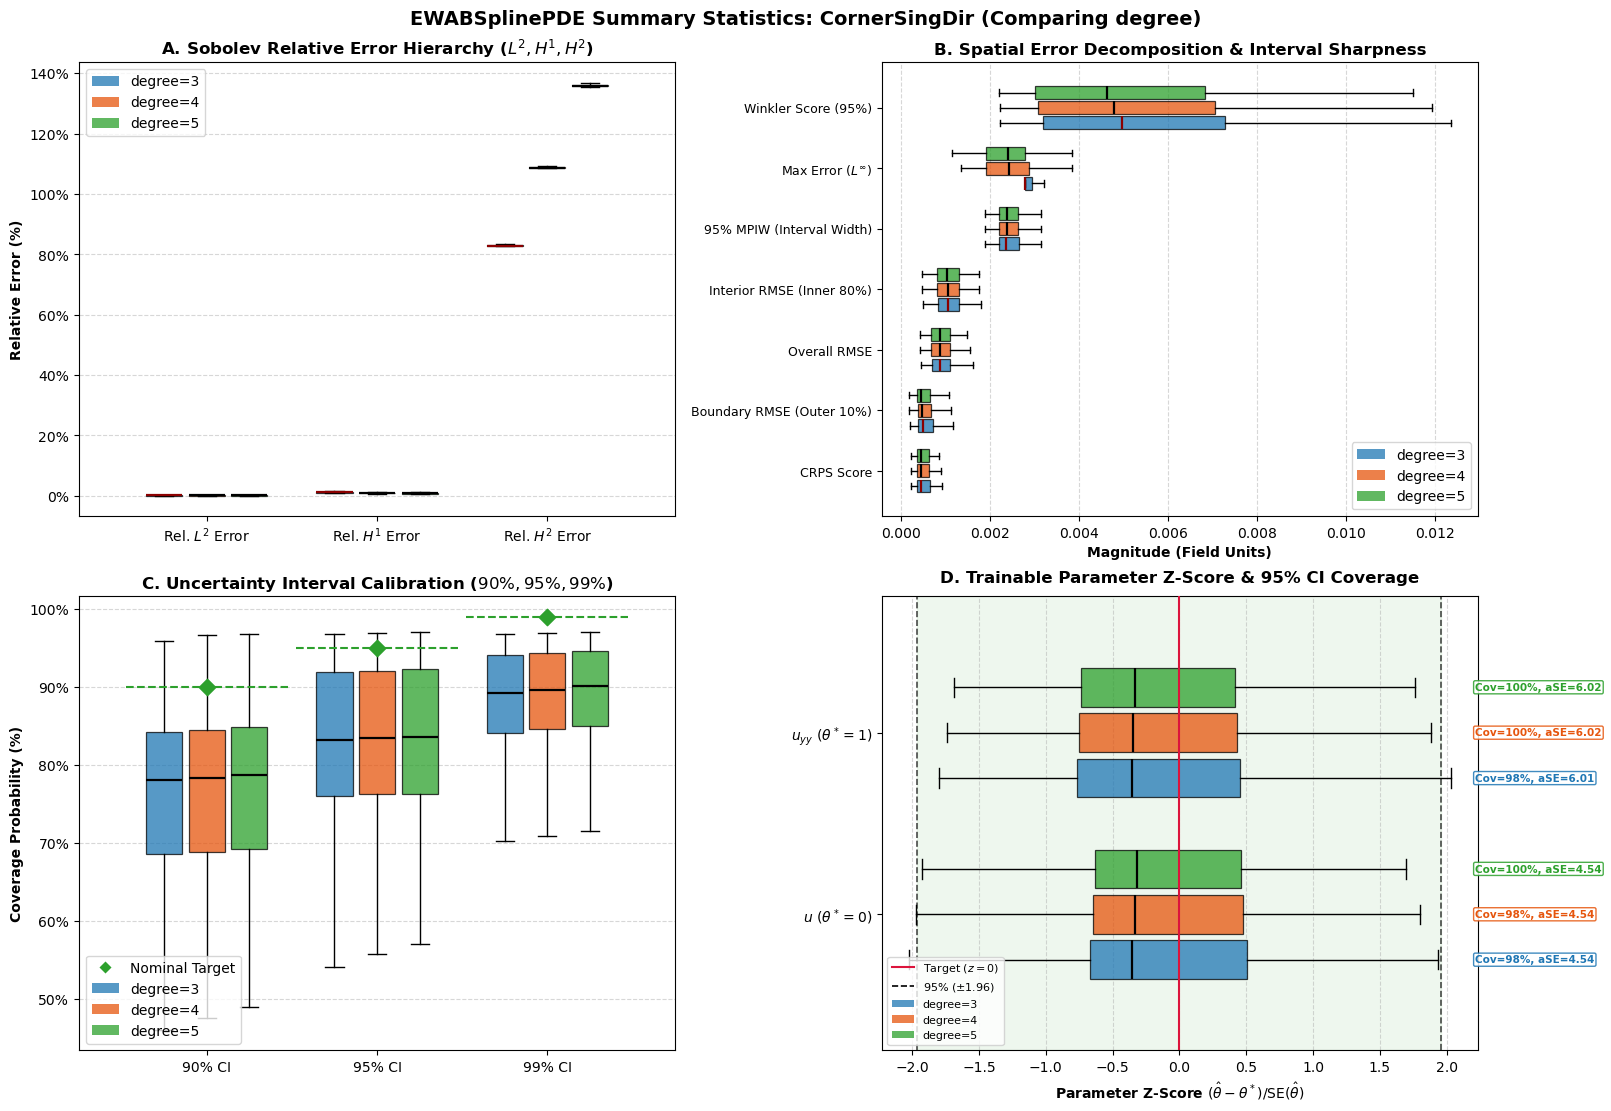

In [8]:
for n in N_list:
    hypothesis('CornerSingDir', n=n)

## 5. Anisotropic Poisson (`PoissonDir.py`)

**PDE:**
$$u_{xx} + a^2 u_{yy} = g(x, y)$$

**Params:**
- Anisotropy: $a = 3.0$ (`p_a`)
- Forcing amplitude: $K = 100.0$ (`p_K`)
- Wavenumber multipliers: $m = 5.0$ (`p_m`), $n = 2.0$ (`p_n`)
- Domain bounds: $L = 2\pi$ (`p_L`), $H = \pi$ (`p_H`)
- Frequencies: $m_2 = \frac{m\pi}{L} = 2.5$, $n_2 = \frac{n\pi}{H} = 2.0$

**Boundary Condition:**
Dirichlet (`boundary_conditions = 'dirichlet'`)

**Domain:**
$$\Omega = [0, L] \times [0, H] = [0, 2\pi] \times [0, \pi]$$

**Force:**
$$g(x, y) = K \cos\left(\frac{m\pi x}{L}\right) \cos\left(\frac{n\pi y}{H}\right) = 100 \cos(2.5 x) \cos(2 y)$$

**Solution:**
$$u(x, y) = -\frac{K}{m_2^2 + (a n_2)^2} \cos\left(\frac{m\pi x}{L}\right) \cos\left(\frac{n\pi y}{H}\right) = -\frac{100}{42.25} \cos(2.5 x) \cos(2 y)$$

100%|███████████████████████████████████████████| 50/50 [03:39<00:00,  4.38s/it]


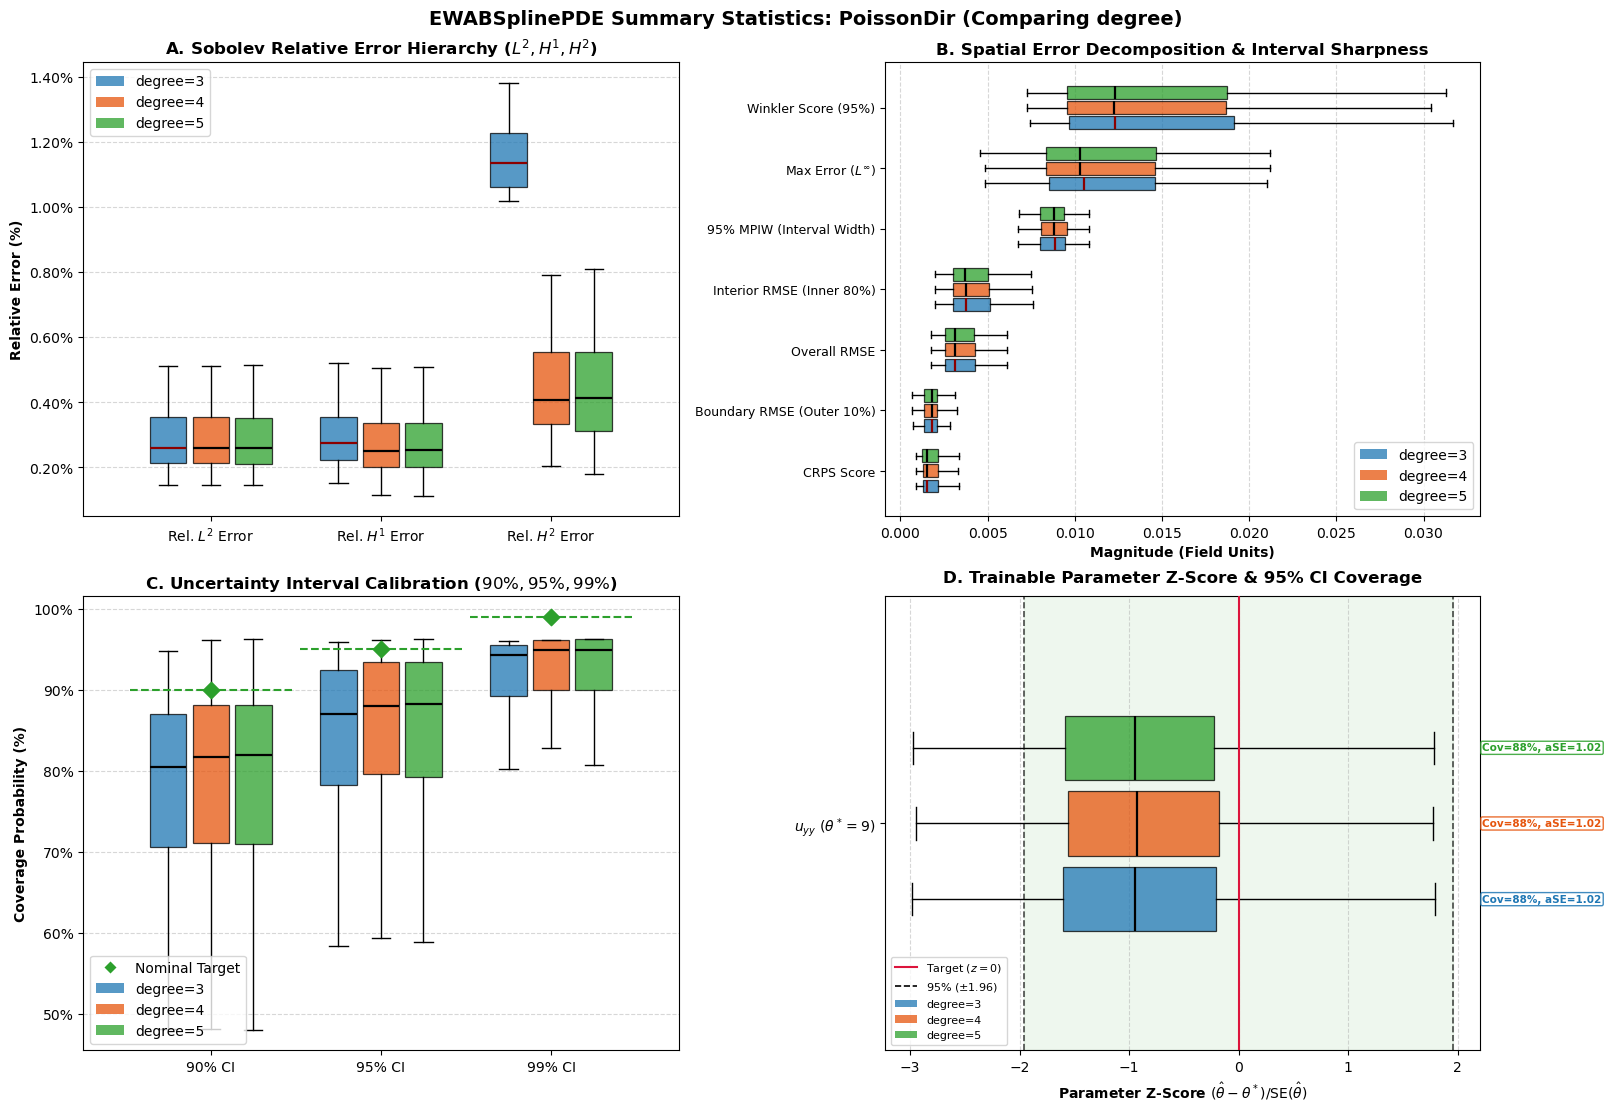

In [9]:
for n in N_list:
    hypothesis('PoissonDir', n=n)

## 6. Tilted Degenerate Diffusion (`DegenEllipNeu.py`)

**PDE:**
$$u_{xx} + b u_{xy} + c u_{yy} = g(x, y)$$

**Params:**
- Cross-diffusion: $b = 1.95$ (`p_b`)
- Diffusion $y$: $c = 1.0$ (`p_c`)
- Modes: $m = 2.0$ (`p_m`), $n = 3.0$ (`p_n`)
- Amplitudes: $a_1 = 1.0$ (`p_a1`), $a_2 = -0.5$ (`p_a2`)
- True parameters: $b = 1.95$ (`b_cross`), $c = 1.0$ (`c_yy`)

**Boundary Condition:**
Neumann (`boundary_conditions = 'neumann'`)

**Domain:**
$$\Omega = [0, 1.0] \times [0, 1.0]$$

**Force:**
$$g(x, y) = u_{xx} + b u_{xy} + c u_{yy}$$

**Solution:**
$$u(x, y) = a_1 \cos(m\pi x) \cos(n\pi y) + a_2 \cos(n\pi x) \cos(m\pi y) = 1.0 \cos(2\pi x) \cos(3\pi y) - 0.5 \cos(3\pi x) \cos(2\pi y)$$

100%|███████████████████████████████████████████| 50/50 [03:36<00:00,  4.33s/it]


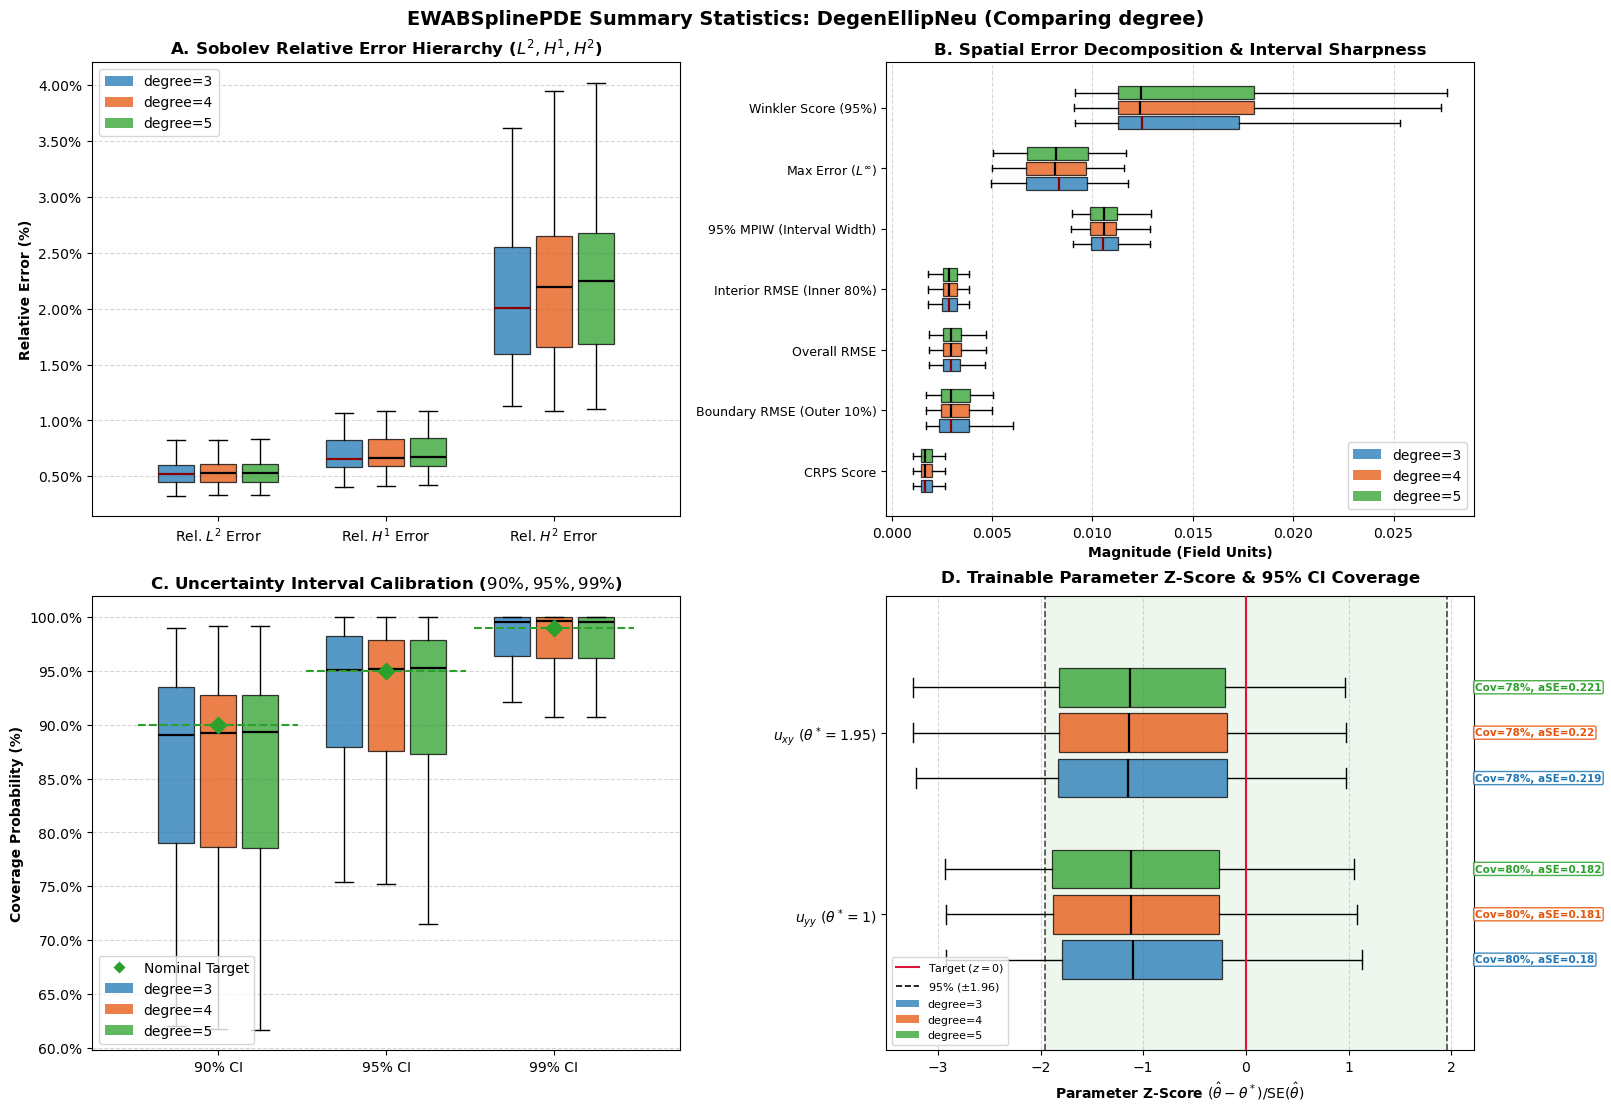

In [10]:
for n in N_list:
    hypothesis('DegenEllipNeu', n=n)

## 7. Zero-Signal / Noise-Only Nullity (`ConstNeu.py`)

**PDE:**
$$u_{xx} + c u_{yy} = 0$$

**Params:**
- Dummy parameter: $1.0$ (`p_dummy`)
- True parameters: `signal_present`: False

**Boundary Condition:**
Neumann (`boundary_conditions = 'neumann'`)

**Domain:**
$$\Omega = [0, 1.0] \times [0, 1.0]$$

**Force:**
$$g(x, y) = 0$$

**Solution:**
$$u(x, y) \equiv 0 \quad \text{everywhere on } \Omega$$

100%|███████████████████████████████████████████| 50/50 [02:10<00:00,  2.60s/it]


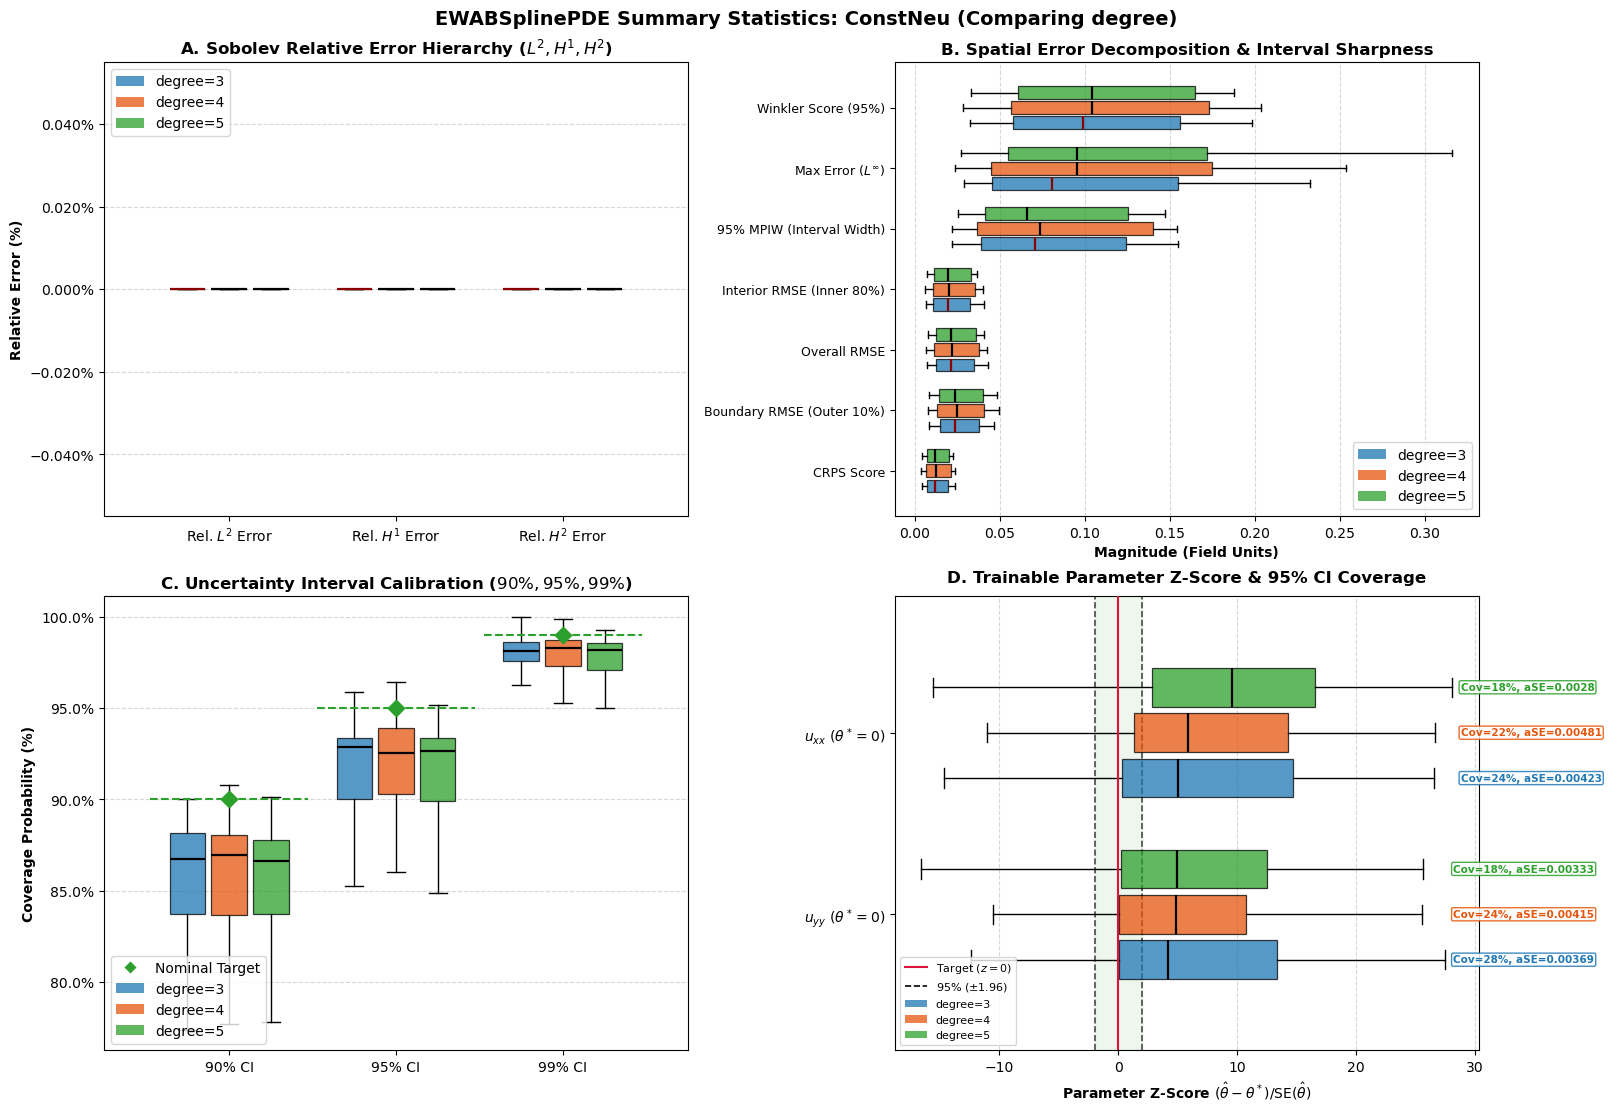

In [11]:
for n in N_list:
    hypothesis('ConstNeu', n=n)

## 8. High-Wavenumber Helmholtz (`HighHelmholtzNeu.py`)

**PDE:**
$$u_{xx} + u_{yy} + k^2 u = 0$$
where $k^2 = (m^2 + n^2)\pi^2 = (5.5^2 + 8.5^2)\pi^2 = 102.5\pi^2 \approx 1011.66$.

**Params:**
- Modes: $m = 5.5$ (`p_m`), $n = 8.5$ (`p_n`)
- Amplitudes: $a_1 = 1.0$ (`p_a1`), $a_2 = -1.0$ (`p_a2`)
- True parameter: $k^2 = 102.5\pi^2$ (`k_sqr`)

**Boundary Condition:**
Neumann (`boundary_conditions = 'neumann'`)

**Domain:**
$$\Omega = [0, 1.0] \times [0, 1.0]$$

**Force:**
$$g(x, y) = 0$$

**Solution:**
$$u(x, y) = a_1 \cos(m\pi x) \cos(n\pi y) + a_2 \cos(n\pi x) \cos(m\pi y) = 1.0 \cos(5.5\pi x) \cos(8.5\pi y) - 1.0 \cos(8.5\pi x) \cos(5.5\pi y)$$

100%|███████████████████████████████████████████| 50/50 [00:53<00:00,  1.07s/it]


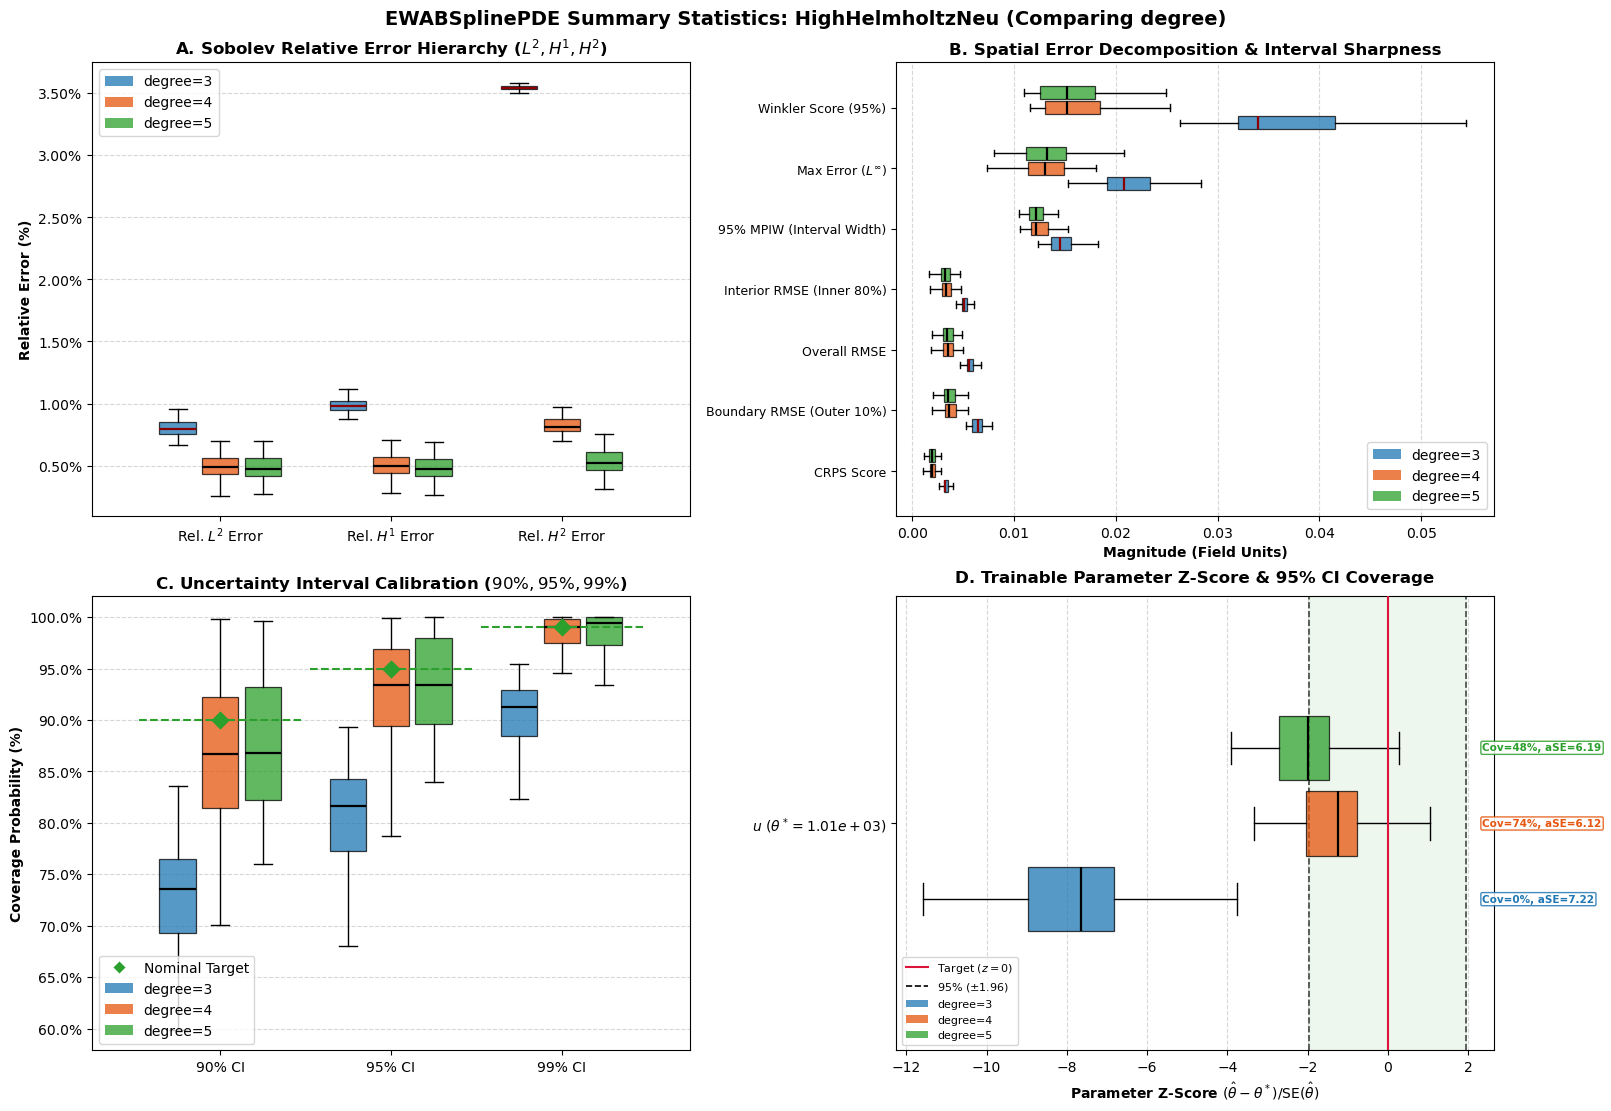

In [12]:
for n in N_list:
    hypothesis('HighHelmholtzNeu', n=n)

## 9. High-Peclet Advection-Diffusion (`HighPecletNeu.py`)

**PDE:**
$$\alpha u_{xx} + u_{yy} - v u_x = 0$$

**Params:**
- Diffusion: $\alpha = 0.01$ (`p_alpha`)
- Velocity: $v = 1.0$ (`p_v`)
- Amplitudes (decay): $a_1 = 1.0$ (`p_a1`), $a_2 = 0.5$ (`p_a2`)
- Amplitudes (boundary layer): $a_{\text{bl},1} = 1.0$ (`p_bl1`), $a_{\text{bl},2} = 0.5$ (`p_bl2`)
- True parameters: $\alpha = 0.01$, $v = 1.0$

**Boundary Condition:**
Dirichlet (`boundary_conditions = 'dirichlet'`)

**Domain:**
$$\Omega = [0, 1.0] \times [0, 1.0]$$

**Force:**
$$g(x, y) = 0$$

**Solution:**
$$u(x, y) = X_1(x) \sin(\pi y) + X_2(x) \sin(2\pi y)$$
where for $k \in \{1, 2\}$:
$$d_k = \sqrt{v^2 + 4\alpha(k\pi)^2}, \quad r_{k,\text{decay}} = \frac{v - d_k}{2\alpha}, \quad r_{k,\text{bl}} = \frac{v + d_k}{2\alpha}$$
$$X_k(x) = a_k e^{r_{k,\text{decay}} x} + a_{\text{bl},k} e^{r_{k,\text{bl}}(x - 1.0)}$$

100%|███████████████████████████████████████████| 50/50 [02:28<00:00,  2.97s/it]


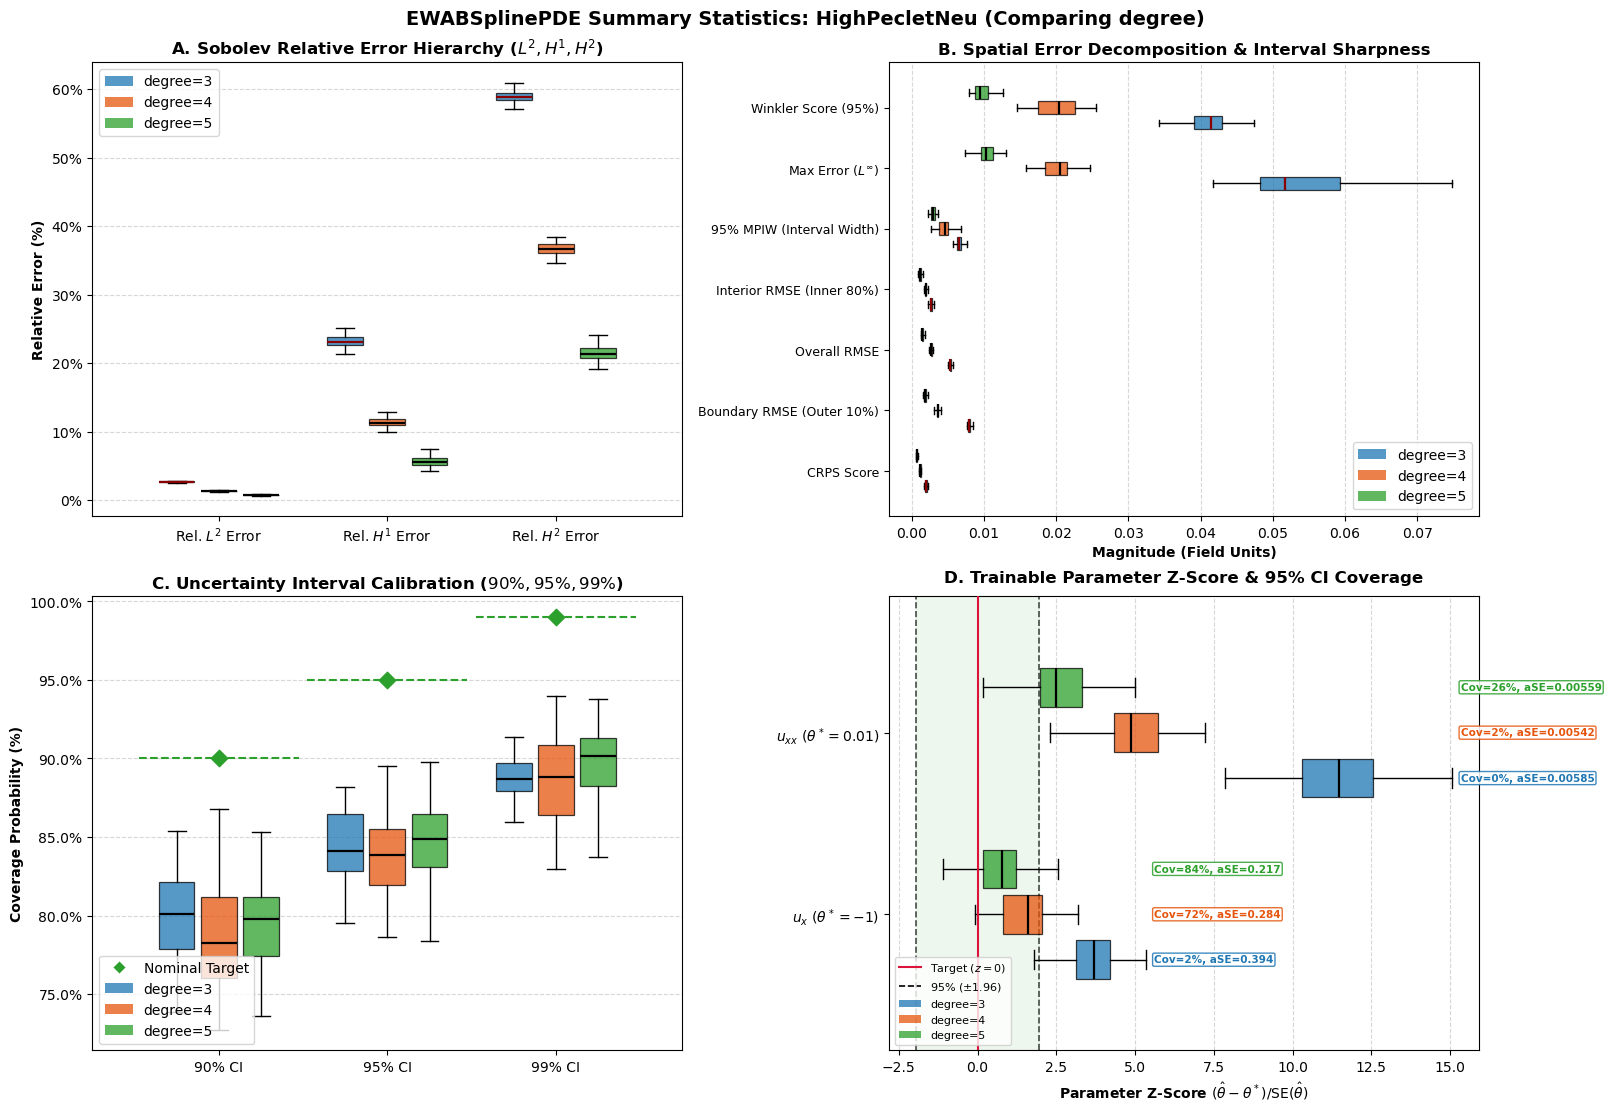

In [13]:
for n in N_list:
    hypothesis('HighPecletNeu', n=n)

## 10. Damped Telegraph Wave (`TelegraphNeu.py`)

**PDE:**
$$u_{yy} + 2\gamma u_y - c^2 u_{xx} = g(x, y) \iff -c^2 u_{xx} + u_{yy} + 2\gamma u_y = g(x, y)$$

**Params:**
- Wave speed: $c = 2.0$ (`p_c`)
- Damping: $\gamma = 0.5$ (`p_gamma`)
- Amplitude: $K = 100.0$ (`p_K`)
- Wavenumber multipliers: $m = 5.0$ (`p_m`), $n = 2.0$ (`p_n`)
- Domain bounds: $L = 2\pi$ (`p_L`), $H = \pi$ (`p_H`)
- Frequencies: $m_2 = \frac{m\pi}{L} = 2.5$, $n_2 = \frac{n\pi}{H} = 2.0$

**Boundary Condition:**
Neumann (`boundary_conditions = 'neumann'`)

**Domain:**
$$\Omega = [0, L] \times [0, H] = [0, 2\pi] \times [0, \pi]$$

**Force:**
$$g(x, y) = K \left( c^2 m_2^2 - n_2^2 - \gamma^2 \right) e^{-\gamma y} \sin(m_2 x) \cos(n_2 y)$$

**Solution:**
$$u(x, y) = K e^{-\gamma y} \sin\left(\frac{m\pi x}{L}\right) \cos\left(\frac{n\pi y}{H}\right) = 100 e^{-0.5 y} \sin(2.5 x) \cos(2 y)$$

100%|███████████████████████████████████████████| 50/50 [01:21<00:00,  1.63s/it]


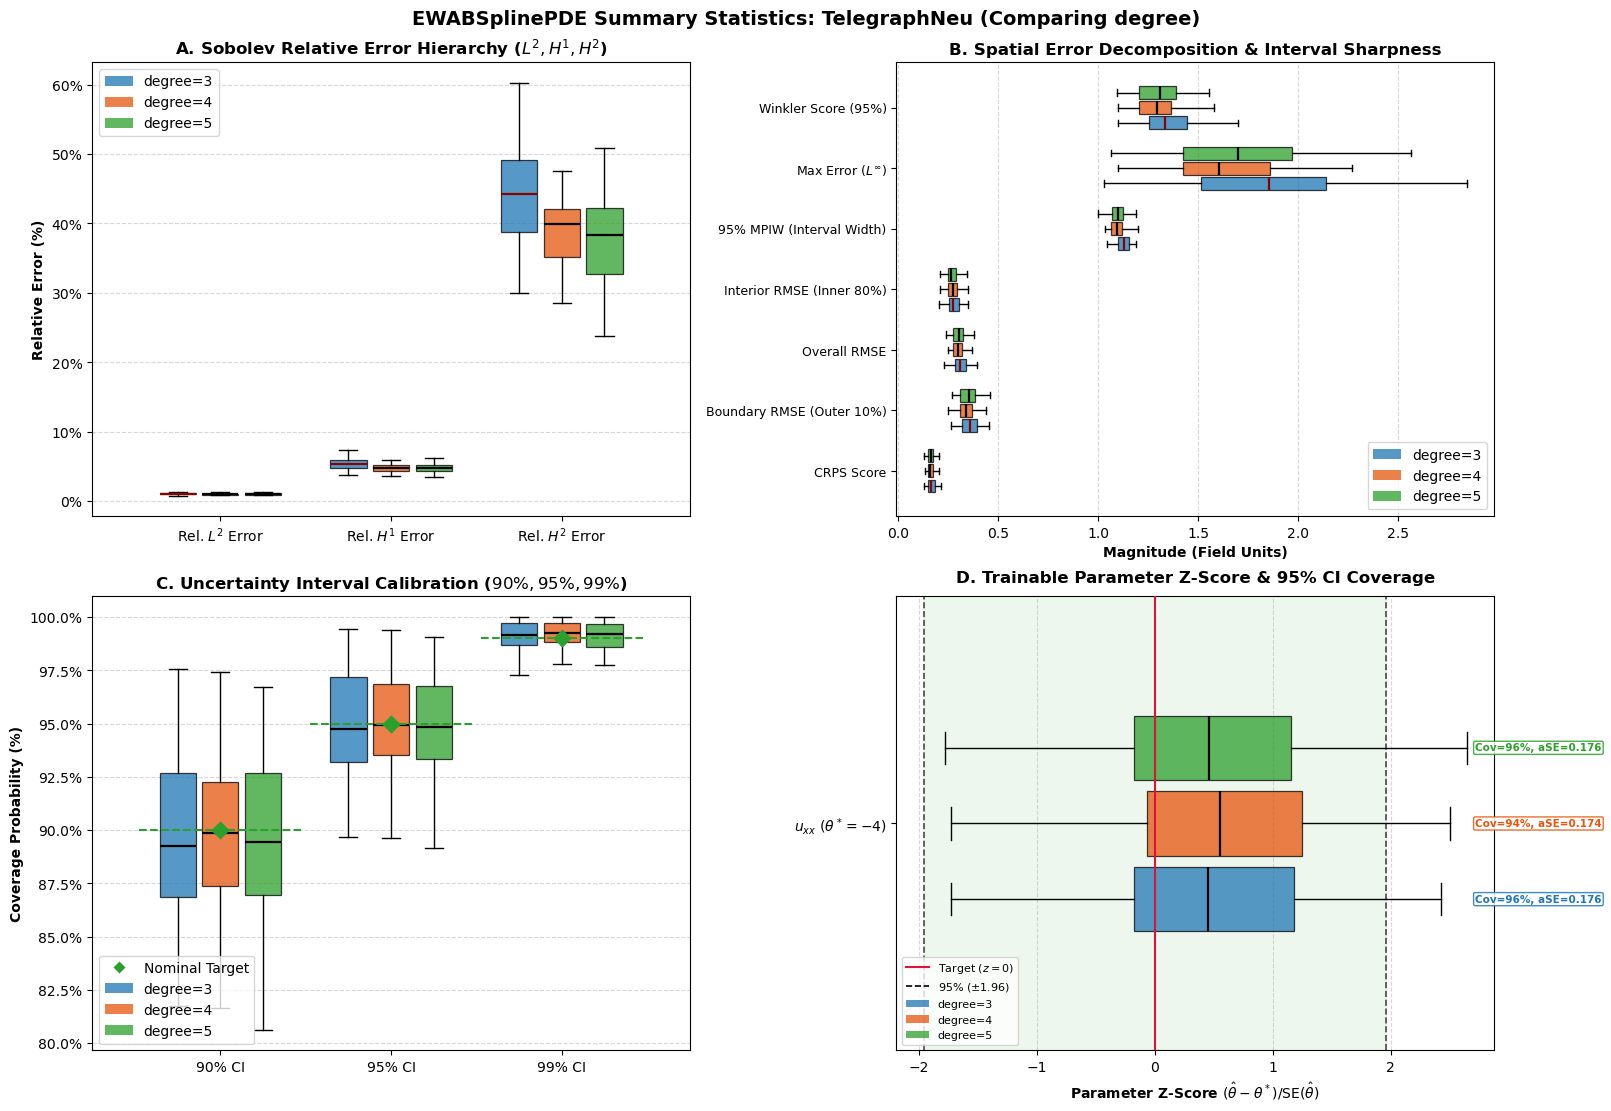

In [14]:
for n in N_list:
    hypothesis('TelegraphNeu', n=n)

## 11. Ill-posed Collinear Harmonic (`CollinHarmNeu.py`)

**PDE:**
$$u_{xx} + c u_{yy} + d u_x = 0$$

**Params:**
- Frequency: $k = 1.0$ (`p_k`)
- Amplitude: $\text{amp} = 1.0$ (`p_amp`)
- True parameters: $c = 1.0$ (`diff_y`), $d = 0.0$ (`vel_x`)

**Boundary Condition:**
Neumann (`boundary_conditions = 'neumann'`)

**Domain:**
$$\Omega = [0, 1.0] \times [0, 1.0]$$

**Force:**
$$g(x, y) = 0$$

**Solution:**
$$u(x, y) = \text{amp} \cdot e^{k x} \sin(k y) = e^x \sin(y)$$

100%|███████████████████████████████████████████| 50/50 [01:32<00:00,  1.85s/it]


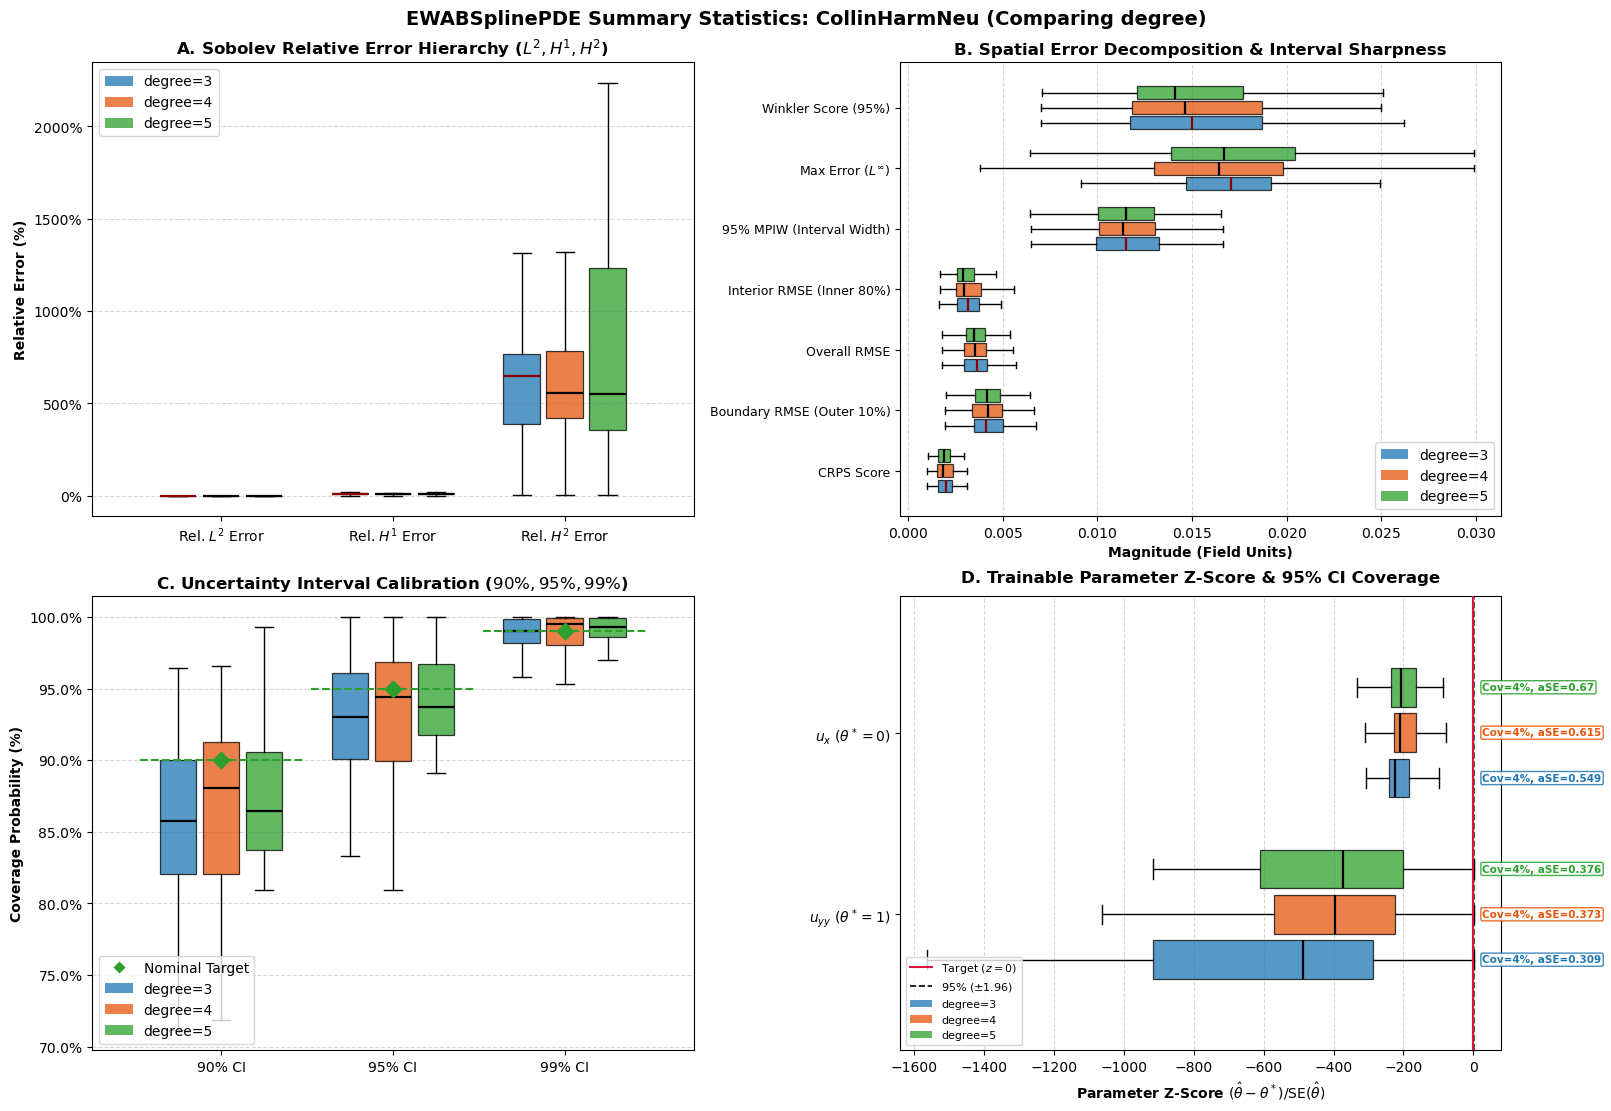

In [15]:
for n in N_list:
    hypothesis('CollinHarmNeu', n=n)